# 05 · Mecânicas de caminhada
Fases 2 a 5 do CRISP-DM aplicadas às mecânicas novas do jogo: **mirantes** (foto a até 40 m de um lugar do mapa), **clima**, **deslocamento impossível** e os **bônus extras** (lupa, desafios, corrente e meta da turma).

> **Dados:** enquanto a turma não joga, este notebook usa `data/processed/capturas_demo.csv` (fictício, gerado por `python -m src.exemplo`). Com o CSV real da página **Avaliação** salvo como `data/processed/avaliacao_juizes.csv`, ele passa a ler esse arquivo sozinho. As conclusões só valem de verdade com os dados reais.

**Perguntas**
1. Em que tipo de lugar cada tema aparece? (é a "pista" que o mapa mostra)
2. A chuva muda o que as pessoas fotografam?
3. A regra de deslocamento impossível barra pouca gente honesta?
4. Quanto dos pontos vem dos bônus novos?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src import jogo
from src.temas import TEMAS

sns.set_theme(style="whitegrid")
REAL = RAIZ / "data" / "processed" / "avaliacao_juizes.csv"
DEMO = RAIZ / "data" / "processed" / "capturas_demo.csv"
ARQUIVO = REAL if REAL.exists() else DEMO
df = pd.read_csv(ARQUIVO, parse_dates=["criado_em"])
NOME_TEMA = {t.id: t.nome for t in TEMAS} | {"nenhum": "nenhum"}
print("Arquivo:", ARQUIVO.name, "| DADOS FICTÍCIOS" if ARQUIVO == DEMO else "| dados reais")
faltam = [c for c in ["mirante", "tipo_lugar", "clima", "km_anterior", "min_anterior", "extra"] if c not in df]
print("Colunas das mecânicas que faltam neste CSV:", faltam or "nenhuma")
df.shape

Arquivo: capturas_demo.csv | DADOS FICTÍCIOS
Colunas das mecânicas que faltam neste CSV: nenhuma


(198, 29)

## 1. Tema × tipo de lugar
Só fotos aceitas tiradas num mirante, onde o app gravou a tag do OpenStreetMap do lugar mais perto.

41 de 151 fotos aceitas (27%) foram em mirantes


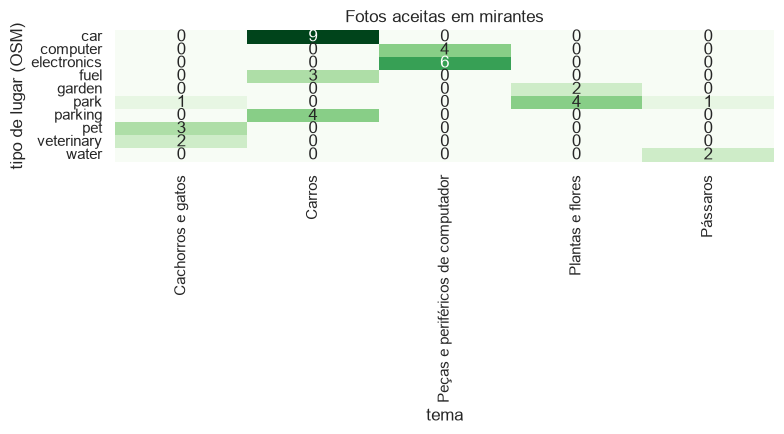

In [2]:
ok = df[df["aceita"].astype(bool)].copy()
mirantes = ok[ok["tipo_lugar"].notna()]
tabela = pd.crosstab(mirantes["tipo_lugar"], mirantes["tema"].map(NOME_TEMA))
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(tabela, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax)
ax.set(xlabel="tema", ylabel="tipo de lugar (OSM)", title="Fotos aceitas em mirantes")
plt.tight_layout()
print(f"{len(mirantes)} de {len(ok)} fotos aceitas ({len(mirantes) / max(len(ok), 1):.0%}) foram em mirantes")

## 2. Clima
Com chuva, plantas e pássaros dão +5 (fora do tema do dia). A pergunta é se isso muda o que se fotografa.

,fotos,aceitas
clima,,
chuva,39,0.79
nublado,78,0.76
sol,73,0.84


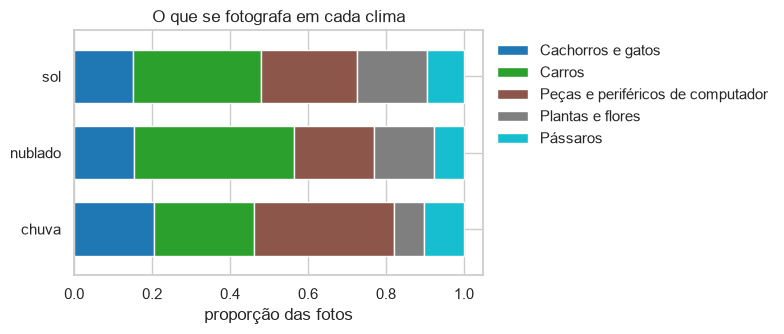

In [3]:
com_clima = df[df["clima"].notna()]
prop = pd.crosstab(com_clima["clima"], com_clima["tema"].map(NOME_TEMA), normalize="index")
fig, ax = plt.subplots(figsize=(8, 3.5))
prop.plot(kind="barh", stacked=True, ax=ax, colormap="tab10", width=.7)
ax.set(xlabel="proporção das fotos", ylabel="", title="O que se fotografa em cada clima")
ax.legend(bbox_to_anchor=(1, 1), loc="upper left", frameon=False)
plt.tight_layout()
com_clima.groupby("clima").agg(fotos=("tema", "size"), aceitas=("aceita", "mean")).round(2)

## 3. Deslocamento impossível
A foto vale 0 quando a pessoa "andou" mais de 3 km a mais de 120 km/h desde a foto anterior. Abaixo de 3 km nada é barrado, para não punir quem está na borda de um quadrado ou com o GPS impreciso.

Barradas por deslocamento: 2 de 190 (1.1%)


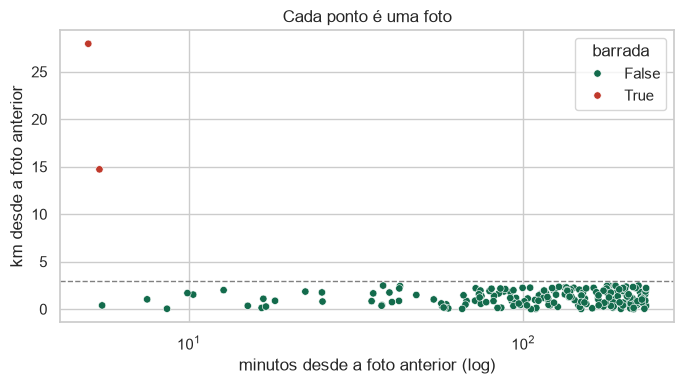

In [4]:
mov = df[df["km_anterior"].notna() & df["min_anterior"].notna()].copy()
mov["kmh"] = mov["km_anterior"] / mov["min_anterior"].clip(lower=1) * 60
mov["barrada"] = [jogo.deslocamento_impossivel(k, m) for k, m in zip(mov["km_anterior"], mov["min_anterior"])]
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=mov, x="min_anterior", y="km_anterior", hue="barrada", palette={False: "#136B4C", True: "#C0392B"},
                ax=ax, s=28)
ax.axhline(jogo.LONGE_KM, ls="--", c="grey", lw=1)
ax.set(xscale="log", xlabel="minutos desde a foto anterior (log)", ylabel="km desde a foto anterior",
       title="Cada ponto é uma foto")
plt.tight_layout()
print(f"Barradas por deslocamento: {mov['barrada'].sum()} de {len(mov)} ({mov['barrada'].mean():.1%})")

## 4. Quanto vem dos bônus
`extra` soma mirante, chuva, lupa, desafios, corrente e meta da turma. Se os extras passarem da metade dos pontos, o jogo vira "caçar bônus" em vez de achar coisas: sinal para baixar os valores.

In [5]:
ok = df[df["aceita"].astype(bool)]
principal = (ok["pontos"] - ok["extra"]).sum()
extras = ok["extra"].sum()
print(f"Pontos principais: {principal:.0f} | extras: {extras:.0f} ({extras / max(principal + extras, 1):.0%} do total)")
por_jogador = ok.groupby("usuario")[["pontos", "extra"]].sum()
por_jogador["% extra"] = (por_jogador["extra"] / por_jogador["pontos"]).round(2)
por_jogador.sort_values("pontos", ascending=False)

Pontos principais: 4808 | extras: 865 (15% do total)


,pontos,extra,% extra
usuario,,,
u08,914,130,0.14
u04,881,140,0.16
u01,843,120,0.14
u06,784,170,0.22
u09,679,120,0.18
u05,539,90,0.17
u07,429,45,0.10
u02,334,40,0.12
u03,270,10,0.04


## 5. Conclusões (preencher com os dados reais)
- **Pistas:** se cada tema se concentra em poucos tipos de lugar, a pista do mirante ajuda; se não, ela pode sair do mapa.
- **Clima:** só faz sentido manter o bônus se a proporção de plantas e pássaros subir com chuva.
- **Deslocamento:** a meta é barrar menos de 2% das fotos. Mais que isso indica GPS ruim ou regra dura demais.
- **Bônus:** extras acima de ~40% dos pontos pedem valores menores.